In [1]:
def load_run_npz(npz_path: str | Path):
    """
    Loads the NPZ and returns a dict with:
      timestamps [datetime64[ns]], counts [uint32], voa_volts [float], pm_volts [float],
      plus the stored metadata (bin_rate_hz_realized, etc.).
    """
    npz_path = Path(npz_path)
    with np.load(npz_path, allow_pickle=True) as z:
        # core arrays
        ts = z["timestamps"].astype("datetime64[ns]")
        counts = z["counts"]
        voa = z["voa_volts"]
        pm  = z["pm_volts"]

        # metadata (may vary depending on options used)
        meta = {k: z[k].item() if z[k].shape == () else z[k]  # scalars as Python types
                for k in z.files
                if k not in {"timestamps", "counts", "voa_volts", "pm_volts"}}

    # quick sanity checks
    if not (len(ts) == len(counts) == len(voa) == len(pm)):
        raise ValueError("Array length mismatch in NPZ (timestamps/counts/voa/pm).")

NameError: name 'Path' is not defined

In [3]:
from typing import Tuple
import numpy as np

def binned_average(
    x, 
    y, 
    n_bins: int
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Compute binned averages of y with respect to x.

    Parameters
    ----------
    x : array-like, shape (N,)
        Independent variable (used for binning).
    y : array-like, shape (N,)
        Dependent variable whose average per bin is returned.
    n_bins : int
        Number of equally-spaced bins between min(x) and max(x).

    Returns
    -------
    bin_edges   : (n_bins+1,) array
        The edges of the bins [left, right].
    bin_centers : (n_bins,) array
        The centers of the bins.
    y_mean      : (n_bins,) array
        Mean of y values falling in each bin (NaN for empty bins).
    counts      : (n_bins,) array
        Number of samples falling in each bin.

    Notes
    -----
    - NaNs in x or y are ignored.
    - The bins are closed on the left and open on the right,
      except the last bin which includes its right edge.
    """
    x = np.asarray(x)
    y = np.asarray(y)

    if x.shape != y.shape:
        raise ValueError("x and y must have the same shape.")
    if n_bins <= 0 or int(n_bins) != n_bins:
        raise ValueError("n_bins must be a positive integer.")

    # Drop NaNs
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if x.size == 0:
        raise ValueError("No finite data left after removing NaNs.")

    # Bin edges and centers
    x_min, x_max = np.min(x), np.max(x)
    if x_min == x_max:
        # All x are identical; put everything in one bin
        n_bins = 1
    edges = np.linspace(x_min, x_max, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    # Assign samples to bins
    # digitize: bins are (edges[i-1], edges[i]] if right=True
    # We want [left, right) except include the very last right edge too.
    idx = np.digitize(x, edges, right=False) - 1  # now nominally [0, n_bins]
    idx = np.clip(idx, 0, n_bins - 1)

    # Use bincount to get sums and counts per bin
    counts = np.bincount(idx, minlength=n_bins)
    sums = np.bincount(idx, weights=y, minlength=n_bins)

    # Avoid division by zero for empty bins
    with np.errstate(invalid="ignore", divide="ignore"):
        means = sums / counts
    means[counts == 0] = np.nan

    return edges, centers, means, counts

In [37]:
#ts = np.loadtxt(r'D:\PhD Thesis Writing\Data\2025-11-18\day2_no_ramp\ni6366_binReq-1000Hz_binReal-1000Hz_AO-250000Hz_VOAreq-2000Hz_VOAreal-2000Hz_mode-finite_20251118T183313+0000.csv',skiprows=1, delimiter=',', usecols=0)
cts = np.loadtxt(r'D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\ni6366_binReq-10000Hz_binReal-10000Hz_AO-250000Hz_VOAreq-52Hz_VOAreal-51.9967Hz_mode-repeat_20251118T174903+0000.csv',skiprows=1, delimiter=',', usecols=1)
voa = np.loadtxt(r'D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\ni6366_binReq-10000Hz_binReal-10000Hz_AO-250000Hz_VOAreq-52Hz_VOAreal-51.9967Hz_mode-repeat_20251118T174903+0000.csv',skiprows=1, delimiter=',', usecols=2)
pm = np.loadtxt(r'D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\ni6366_binReq-10000Hz_binReal-10000Hz_AO-250000Hz_VOAreq-52Hz_VOAreal-51.9967Hz_mode-repeat_20251118T174903+0000.csv',skiprows=1, delimiter=',', usecols=3)

In [39]:
ns=[]
for i in range(len(cts)):
    ns.append(i)

In [13]:
from matplotlib import pyplot as plt

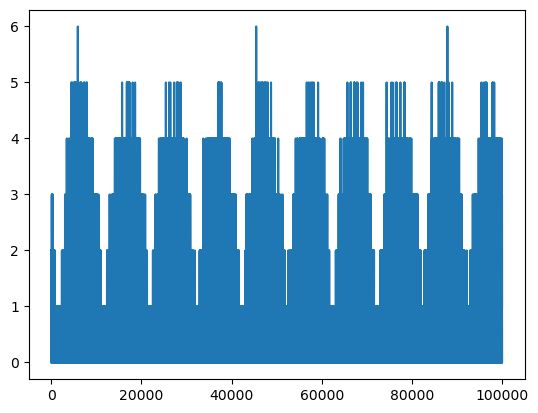

In [41]:
plt.plot(ns,cts)

In [43]:
edges, centers, y_mean, counts = binned_average(ns, cts, n_bins=4000)

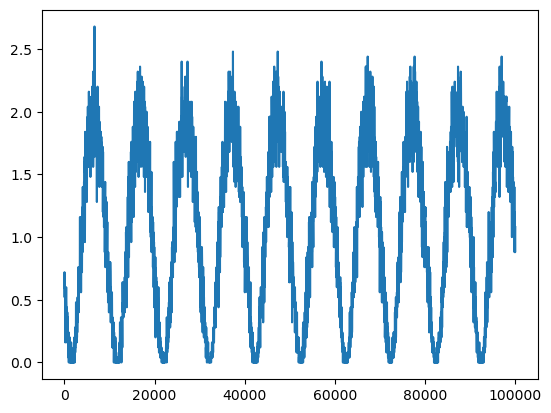

In [45]:
plt.plot(centers,y_mean)